This is the notebook for cleaning and wrangling the wetlands shapefile. Steps include:
1. Adding the Hectares column and subsetting the data to polygons larger than 1 Hectare.
2. Removing shapefile length, shapefile area, and QAQC. 

### Data Quality Audit & Preliminary Exploratory Analysis
Due to the large number of wetland polygons in California provided by the NWI (~900,000), the data was subset to only include wetland parcels larger than 1 HA (10000m^2). 21% of all California wetlands will be included in our analysis. This means that there will be inherent “missingness" within our dataset because smaller wetlands and small offshoots of wetland complexes are excluded from our analysis. There are no duplicates or implausible values within our dataset (Palustrine subsystems are N/A because there are none). The other data quality element performed on these dataframes was the parsing of the Cowardin Codes into columns labelled for system, subsystem, and class.

We began with 891,086 rows,and 9 columns, but after subsetting to only include wetlands greater than a hectare, we are left with 179,139 rows. 
Some columns with information deemed unimportant that also contained missing values or were duplicates were dropped: 'QAQC_CODE', 'Shape_Leng', 'Shape_Area', and 'ACRES'.

In [18]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import pygris
import matplotlib.pyplot as plt
import plotly 
import plotly.graph_objects as go

Access Initial Shapefile from Box Drive and read in the shapefile

In [2]:
# set a path to the main box folder based on machine's os
# if windows: 
if platform.system() == 'Windows':
    box_path = Path.home() / 'Box'
# if mac:
else:
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"

#Confirm that the box path is valid
if box_path.exists():
    print(f'Box folder found at {box_path}')
else:
    print(f'Failed to locate the Box folder.\nIs the BoxDrive app running?\nAre you logged in?')

# create path object that goes to the specific folder on Box drive
# uploading wetlands that are bigger than a hectare
wetlands_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'wetlands' / 'wetlands.shp'
print(wetlands_path.exists())



Box folder found at /Users/masonbunker/Library/CloudStorage/Box-Box
True


In [3]:
#read in shp, be PATIENT (took MB 4.5 mins)
wetlands_shp = gpd.read_file(wetlands_path)

Find out information from the wetlands shapefile

In [4]:
wetlands_shp.shape
wetlands_shp.columns


Index(['OBJECTID', 'ATTRIBUTE', 'WETLAND_TY', 'QAQC_CODE', 'ACRES', 'NWI_ID',
       'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='str')

In [5]:
wetlands_shp.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 891086 entries, 0 to 891085
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   OBJECTID    891086 non-null  float64 
 1   ATTRIBUTE   891086 non-null  str     
 2   WETLAND_TY  891086 non-null  str     
 3   QAQC_CODE   22260 non-null   str     
 4   ACRES       891086 non-null  float64 
 5   NWI_ID      891086 non-null  str     
 6   Shape_Leng  891086 non-null  float64 
 7   Shape_Area  891086 non-null  float64 
 8   geometry    891086 non-null  geometry
dtypes: float64(4), geometry(1), str(4)
memory usage: 61.2 MB


Subset the data to only include polygons larger than 1 Hectare (10,000m^2), roughly 20% of the initial data set.

In [6]:
wetlands_shp["Hectares"] = wetlands_shp["Shape_Area"]/10000

wetlands_hectare = wetlands_shp.loc[lambda df: df["Hectares"] > 1]

wetlands_hectare.shape

#calculate subset percent
subset = 179139/891086*100
print(subset)

20.103446805358853


Determine appropriate columns to remain in the cleaned dataset.

In [7]:
wetlands_hectare.head()

,OBJECTID,ATTRIBUTE,WETLAND_TY,QAQC_CODE,ACRES,NWI_ID,Shape_Leng,Shape_Area,geometry,Hectares
2,3.0,R4SBC,Riverine,NaN,9.394554,202409CSw{B818AEF7-DD4D-43B6-A532-1DC94D248F88...,12669.925427,38018.410790,"POLYGON ((-2195423.854 1489042.416, -2195423.8...",3.801841
9,10.0,R4SBC,Riverine,NaN,4.869321,202409CSw{80E28DA5-6244-45AB-9DC9-774ACABD2846...,6572.482823,19705.442594,"POLYGON ((-2197428.286 1494975.476, -2197428.3...",1.970544
11,12.0,R4SBC,Riverine,NaN,7.364585,202409CSw{A66FA93B-E12A-488A-9891-E7526D1AACCE...,9937.020983,29803.416122,"POLYGON ((-2193923.26 1496246.62, -2193923.139...",2.980342
12,13.0,R4SBC,Riverine,NaN,3.099673,202409CSw{B5A926CC-AF98-487F-A4B9-A4789311100A...,4194.847948,12543.932403,"POLYGON ((-2194477.48 1496368.039, -2194475.19...",1.254393
14,15.0,R4SBC,Riverine,NaN,20.027313,202409CSw{C99C89FF-6622-43DE-A93F-138503071611...,26989.063820,81047.662073,"POLYGON ((-2195115.466 1496641.214, -2195115.3...",8.104766


Subset to only Core Columns and rename to be more appropriate

In [8]:
core_cols = ["ATTRIBUTE", "WETLAND_TY","Hectares", "NWI_ID", "geometry"]

wetlands = wetlands_hectare[core_cols]

In [9]:
wetlands = wetlands.rename(
    columns={
        "ATTRIBUTE" : "C Code",
        "WETLAND_TY" : "NWI Type",
        "NWI_ID": "NWI ID"
    }
)

wetlands.head()
#wetlands.shape

,C Code,NWI Type,Hectares,NWI ID,geometry
2,R4SBC,Riverine,3.801841,202409CSw{B818AEF7-DD4D-43B6-A532-1DC94D248F88...,"POLYGON ((-2195423.854 1489042.416, -2195423.8..."
9,R4SBC,Riverine,1.970544,202409CSw{80E28DA5-6244-45AB-9DC9-774ACABD2846...,"POLYGON ((-2197428.286 1494975.476, -2197428.3..."
11,R4SBC,Riverine,2.980342,202409CSw{A66FA93B-E12A-488A-9891-E7526D1AACCE...,"POLYGON ((-2193923.26 1496246.62, -2193923.139..."
12,R4SBC,Riverine,1.254393,202409CSw{B5A926CC-AF98-487F-A4B9-A4789311100A...,"POLYGON ((-2194477.48 1496368.039, -2194475.19..."
14,R4SBC,Riverine,8.104766,202409CSw{C99C89FF-6622-43DE-A93F-138503071611...,"POLYGON ((-2195115.466 1496641.214, -2195115.3..."


Write a function to fill in the columns for Cowardin (C) Subsystem and Class

In [10]:
# create additional columns for subsystem and class
wetlands.insert(2, "C System", None)
wetlands.insert(3, "C Subsystem", None)
wetlands.insert(4, "C Class", None)

wetlands.head()

,C Code,NWI Type,C System,C Subsystem,C Class,Hectares,NWI ID,geometry
2,R4SBC,Riverine,None,None,None,3.801841,202409CSw{B818AEF7-DD4D-43B6-A532-1DC94D248F88...,"POLYGON ((-2195423.854 1489042.416, -2195423.8..."
9,R4SBC,Riverine,None,None,None,1.970544,202409CSw{80E28DA5-6244-45AB-9DC9-774ACABD2846...,"POLYGON ((-2197428.286 1494975.476, -2197428.3..."
11,R4SBC,Riverine,None,None,None,2.980342,202409CSw{A66FA93B-E12A-488A-9891-E7526D1AACCE...,"POLYGON ((-2193923.26 1496246.62, -2193923.139..."
12,R4SBC,Riverine,None,None,None,1.254393,202409CSw{B5A926CC-AF98-487F-A4B9-A4789311100A...,"POLYGON ((-2194477.48 1496368.039, -2194475.19..."
14,R4SBC,Riverine,None,None,None,8.104766,202409CSw{C99C89FF-6622-43DE-A93F-138503071611...,"POLYGON ((-2195115.466 1496641.214, -2195115.3..."


In [11]:
# generate function to determine the Systems
def assign_system(df):
    df.loc[lambda df: df["C Code"].str.startswith("M", na = False), "C System"] = 'Marine'
    df.loc[lambda df: df["C Code"].str.startswith("E", na = False), "C System"] = 'Estuarine'
    df.loc[lambda df: df["C Code"].str.startswith("R", na = False), "C System"] = 'Riverine'
    df.loc[lambda df: df["C Code"].str.startswith("L", na = False), "C System"] = 'Lacustrine'
    df.loc[lambda df: df["C Code"].str.startswith("P", na = False), "C System"] = 'Palustrine'

    return df

#apply system function
wetlands = assign_system(wetlands)
wetlands.sample(5)


,C Code,NWI Type,C System,C Subsystem,C Class,Hectares,NWI ID,geometry
468237,PSS1B,Freshwater Forested/Shrub Wetland,Palustrine,None,None,1.987082,202409CSw{993E0E7A-F07B-49B7-9D1B-E944F11A5D95...,"POLYGON ((-2299872.058 1990920.264, -2299879.4..."
351672,PEM1B,Freshwater Emergent Wetland,Palustrine,None,None,1.358941,202409CSw{43C8F552-1BFA-4296-A9F2-9615DB9364B4...,"POLYGON ((-1964188.602 1727752.859, -1964188.6..."
465693,PUBHx,Freshwater Pond,Palustrine,None,None,1.235801,202409CSw{9D836989-9B07-46EC-8704-B14EF35E6850...,"POLYGON ((-2287398.13 2013981.3, -2287409.79 2..."
440640,PEM1Ch,Freshwater Emergent Wetland,Palustrine,None,None,6.159940,202409CSw{304DE613-DF3D-431F-A2AF-713377260AD0...,"POLYGON ((-2267245.214 1975460.527, -2267249.0..."
154585,R5UBFx,Riverine,Riverine,None,None,1.552672,202409CSw{086F3208-338F-4BC1-A871-44701B236882...,"POLYGON ((-2055061.782 1764807.284, -2055069.1..."


In [12]:
# generate function to determine the Subsystems
def assign_subsystem(df):
    # marine
    df.loc[lambda df: df["C Code"].str.startswith("M1", na = False), "C Subsystem"] = 'Subtidal'
    df.loc[lambda df: df["C Code"].str.startswith("M2", na = False), "C Subsystem"] = 'Intertidal' 
    # estuarine
    df.loc[lambda df: df["C Code"].str.startswith("E1", na = False), "C Subsystem"] = 'Subtidal'
    df.loc[lambda df: df["C Code"].str.startswith("E2", na = False), "C Subsystem"] = 'Intertidal' 
    # riverine
    df.loc[lambda df: df["C Code"].str.startswith("R1", na = False), "C Subsystem"] = 'Tidal'
    df.loc[lambda df: df["C Code"].str.startswith("R2", na = False), "C Subsystem"] = 'Lower Perennial'
    df.loc[lambda df: df["C Code"].str.startswith("R3", na = False), "C Subsystem"] = 'Upper Perennial'
    df.loc[lambda df: df["C Code"].str.startswith("R4", na = False), "C Subsystem"] = 'Intermittent'
    df.loc[lambda df: df["C Code"].str.startswith("R5", na = False), "C Subsystem"] = 'Unknown Perennial'

    # lacustrine
    df.loc[lambda df: df["C Code"].str.startswith("L1", na = False), "C Subsystem"] = 'Limnetic'
    df.loc[lambda df: df["C Code"].str.startswith("L2", na = False), "C Subsystem"] = 'Littoral'
    # palustrine
    df.loc[lambda df: df["C Code"].str.startswith("P", na = False), "C Subsystem"] = "N/A"
    
    return df

## apply the subsystem function
wetlands = assign_subsystem(wetlands)

wetlands.head(12)

,C Code,NWI Type,C System,C Subsystem,C Class,Hectares,NWI ID,geometry
2,R4SBC,Riverine,Riverine,Intermittent,None,3.801841,202409CSw{B818AEF7-DD4D-43B6-A532-1DC94D248F88...,"POLYGON ((-2195423.854 1489042.416, -2195423.8..."
9,R4SBC,Riverine,Riverine,Intermittent,None,1.970544,202409CSw{80E28DA5-6244-45AB-9DC9-774ACABD2846...,"POLYGON ((-2197428.286 1494975.476, -2197428.3..."
11,R4SBC,Riverine,Riverine,Intermittent,None,2.980342,202409CSw{A66FA93B-E12A-488A-9891-E7526D1AACCE...,"POLYGON ((-2193923.26 1496246.62, -2193923.139..."
12,R4SBC,Riverine,Riverine,Intermittent,None,1.254393,202409CSw{B5A926CC-AF98-487F-A4B9-A4789311100A...,"POLYGON ((-2194477.48 1496368.039, -2194475.19..."
14,R4SBC,Riverine,Riverine,Intermittent,None,8.104766,202409CSw{C99C89FF-6622-43DE-A93F-138503071611...,"POLYGON ((-2195115.466 1496641.214, -2195115.3..."
18,R4SBC,Riverine,Riverine,Intermittent,None,6.543216,202409CSw{2748E15A-8C19-45BE-B3AE-EF4D3462394D...,"POLYGON ((-2204235.899 1502866.581, -2204233.8..."
19,R4SBC,Riverine,Riverine,Intermittent,None,2.289157,202409CSw{A9FC265B-A070-49F6-91EB-1AF1B24F270E...,"POLYGON ((-2212223.548 1504505.924, -2212221.2..."
21,R4SBC,Riverine,Riverine,Intermittent,None,1.366831,202409CSw{02608E9D-9216-4FBD-802A-AAD2E4A3047C...,"POLYGON ((-2211172.156 1506003.818, -2211172.0..."
34,R5UBF,Riverine,Riverine,Unknown Perennial,None,3.483020,202409CSw{731BDF60-58CE-48ED-9DB8-7558C8FC3E8E...,"POLYGON ((-2193015.598 1494952.847, -2193014.2..."
35,R4SBC,Riverine,Riverine,Intermittent,None,1.250247,202409CSw{A80FA3E0-6491-4C92-95B6-4AB6D195B8B2...,"POLYGON ((-2195615.688 1490047.353, -2195617.4..."


In [13]:
#generate function to determine the Classes
def assign_class(df):
    df.loc[lambda df: df["C Code"].str.contains("SB", na = False), "C Class"] = "Streambed"
    df.loc[lambda df: df["C Code"].str.contains("RB", na = False), "C Class"] = "Rock Bottom"
    df.loc[lambda df: df["C Code"].str.contains("UB", na = False), "C Class"] = "Unconsolidated Bottom"
    df.loc[lambda df: df["C Code"].str.contains("AB", na = False), "C Class"] = "Aquatic Bed"
    df.loc[lambda df: df["C Code"].str.contains("RF", na = False), "C Class"] = "Reef"
    df.loc[lambda df: df["C Code"].str.contains("RS", na = False), "C Class"] = "Rocky Shore"
    df.loc[lambda df: df["C Code"].str.contains("US", na = False), "C Class"] = "Unconsolidated Shore"
    df.loc[lambda df: df["C Code"].str.contains("EM", na = False), "C Class"] = "Emergent"
    df.loc[lambda df: df["C Code"].str.contains("SS", na = False), "C Class"] = "Scrub-Shrub"
    df.loc[lambda df: df["C Code"].str.contains("FO", na = False), "C Class"] = "Forested"
    df.loc[lambda df: df["C Code"].str.contains("ML", na = False), "C Class"] = "Moss-Lichen"
    
    return df

wetlands = assign_class(wetlands)

wetlands.sample(12)
wetlands.shape

(179139, 8)

Do the same process for the full data set

In [14]:
core_cols = ["ATTRIBUTE", "WETLAND_TY","Hectares", "NWI_ID", "geometry"]

wetlands_all = wetlands_shp[core_cols]

wetlands_all = wetlands_all.rename(
    columns={
        "ATTRIBUTE" : "C Code",
        "WETLAND_TY" : "NWI Type",
        "NWI_ID": "NWI ID"
    }
)

wetlands_all.insert(2, "C System", None)
wetlands_all.insert(3, "C Subsystem", None)
wetlands_all.insert(4, "C Class", None)

wetlands_all = assign_system(wetlands_all)
wetlands_all = assign_subsystem(wetlands_all)
wetlands_all = assign_class(wetlands_all)


wetlands_all.shape



(891086, 8)

Export new shapefile  into box

In [14]:
# confirm box path still works

# if windows: 
if platform.system() == 'Windows':
    box_path = Path.home() / 'Box'
# if mac:
else:
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"

#Confirm that the box path is valid
if box_path.exists():
    print(f'Box folder found at {box_path}')
else:
    print(f'Failed to locate the Box folder.\nIs the BoxDrive app running?\nAre you logged in?')

# create path object that goes to the specific folder on Box drive
wetlands_subset_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'wetlands_subset'

#comment out bc not sure what this is doing? the path is defined in later code block
# print(wetlands_subset_gpkg_path.exists())

Box folder found at /Users/masonbunker/Library/CloudStorage/Box-Box


In [ ]:
# actually save to the the folder

# this works to download to a local copy
wetlands.to_file("wetlands_subset.geojson", driver= "GeoJSON")

In [ ]:
# save just first 10 rows as a test
wetlands.iloc[:10].to_file(wetlands_subset_path/"wetlands_subset_first10.geojson", driver = "GeoJSON")

In [ ]:
# try to save it all
wetlands.to_file(wetlands_subset_path/"wetlands_subset.geojson", driver = "GeoJSON")

Confirm that the export worked and the file can be read in.

In [25]:
# create path object that goes to the specific folder on Box drive
wetlands_subset_gpkg_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'wetlands_subset' / 'wetlands_subset_first10.geojson'
print("It is", wetlands_subset_gpkg_path.exists(), "that the file exists.")

It is True that the file exists.


In [ ]:
# read in shp, be PATIENT
wetlands_subset = gpd.read_file(wetlands_subset_gpkg_path)

In [27]:
wetlands_subset.shape

(179139, 8)

Create a map of CA Wetlands!

Using the default year of 2024


Text(0.5, 1.0, 'California Wetlands by Cowardin Classification')

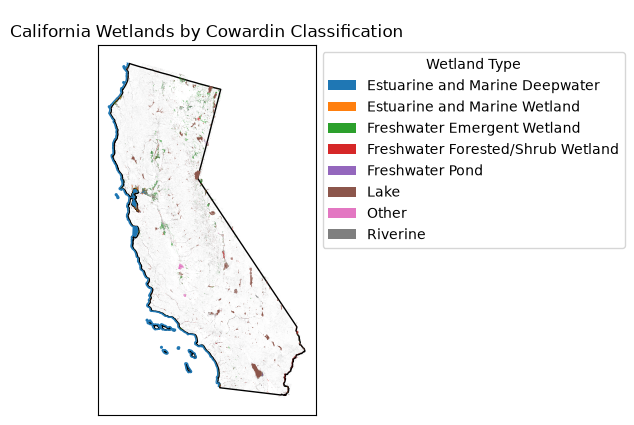

In [86]:
# make a plot of CA wetlands
state_outlines = pygris.states()
state_outlines.head()
ca_outline = state_outlines[state_outlines['NAME'] == 'California']

# make sure CA and wetlands shapefile are in same CRS
ca_outline_proj= ca_outline.to_crs(wetlands1.crs)


# create the empty plot

fig, ax = plt.subplots()
# add the CA outline
ca_outline_proj.plot(ax=ax,color='white',edgecolor='black')
# add the wetlands
# set color by cowardin classification? Legend advice from google gemini
wetlands.plot(column='NWI Type',legend=True,ax=ax,figsize=(10,10),
               legend_kwds={
        'loc': 'upper left',       # Moves it to the corner
        'bbox_to_anchor': (1, 1),  # Places it entirely outside the map boundaries
        'title': 'Wetland Type'    # Optional: adds a neat title to your legend box
    })

# consult google gemini to learn how to turn axes off
ax.axis=('off')
ax.get_xaxis().set_visible(False) 
ax.get_yaxis().set_visible(False)

ax.set_title("California Wetlands by Cowardin Classification")


In [26]:
#compare df sizes with names
print("all:", wetlands_all.shape)
print("subset:", wetlands.shape)

#compare new dfs sizes for the sankey
print("for sankey")
print("all:", df.shape)
print("subset:", df2.shape)

all: (891086, 8)
subset: (179139, 8)
for sankey
all: (179139, 8)
subset: (891086, 8)


In [33]:
# this code was generated with the help of chatgpt to best understand the manipulation of a sankey diagram.

df = wetlands.copy()

df["Hectares"] = pd.to_numeric(df["Hectares"], errors="coerce")
df = df.dropna(subset=["Hectares"])

cols = ["C System", "C Subsystem", "C Class"]

for col in cols:
    df[col] = df[col].fillna("Unknown").astype(str)

# 2. Calculate total hectares for each transition
flow1 = (
    df.groupby(["C System", "C Subsystem"])["Hectares"]
    .sum()
    .reset_index()
)

flow2 = (
    df.groupby(["C Subsystem", "C Class"])["Hectares"]
    .sum()
    .reset_index()
)

# 3. Create separate nodes for each classification level
systems = df["C System"].unique().tolist()
subsystems = df["C Subsystem"].unique().tolist()
classes = df["C Class"].unique().tolist()

labels = (
    [f"System: {x}" for x in systems]
    + [f"Subsystem: {x}" for x in subsystems]
    + [f"Class: {x}" for x in classes]
)

system_map = {x: i for i, x in enumerate(systems)}

subsystem_map = {
    x: i + len(systems)
    for i, x in enumerate(subsystems)
}

class_map = {
    x: i + len(systems) + len(subsystems)
    for i, x in enumerate(classes)
}

# 4. Build links
sources = (
    flow1["C System"].map(system_map).tolist()
    + flow2["C Subsystem"].map(subsystem_map).tolist()
)

targets = (
    flow1["C Subsystem"].map(subsystem_map).tolist()
    + flow2["C Class"].map(class_map).tolist()
)

values = (
    flow1["Hectares"].tolist()
    + flow2["Hectares"].tolist()
)

# 5. Generate the Sankey diagram
fig_subset = go.Figure(go.Sankey(
    node=dict(label=labels),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        hovertemplate=(
            "%{source.label} → %{target.label}<br>"
            "Area: %{value:,.2s} hectares"
            "<extra></extra>"
        )
    )
))

fig_subset.update_layout(
    title="Wetland Area in Hectares for California Wetlands larger than 1ha by Cowardin System, Subsystem, and Class",
    font_size=11,
    width=1100,
    height=700
)

fig_subset.show()

In [34]:
# same as above but for all wetlands in the NWI CA dataset

# 1. Prepare data
df2 = wetlands_all.copy()

df2["Hectares"] = pd.to_numeric(df2["Hectares"], errors="coerce")
df2 = df2.dropna(subset=["Hectares"])

cols2 = ["C System", "C Subsystem", "C Class"]

for col in cols2:
    df2[col] = df2[col].fillna("Unknown").astype(str)

# 2. Calculate total hectares for each transition
flow1 = (
    df2.groupby(["C System", "C Subsystem"])["Hectares"]
    .sum()
    .reset_index()
)

flow2 = (
    df2.groupby(["C Subsystem", "C Class"])["Hectares"]
    .sum()
    .reset_index()
)

# 3. Create separate nodes for each classification level
systems = df2["C System"].unique().tolist()
subsystems = df2["C Subsystem"].unique().tolist()
classes = df2["C Class"].unique().tolist()

labels = (
    [f"System: {x}" for x in systems]
    + [f"Subsystem: {x}" for x in subsystems]
    + [f"Class: {x}" for x in classes]
)

system_map = {x: i for i, x in enumerate(systems)}

subsystem_map = {
    x: i + len(systems)
    for i, x in enumerate(subsystems)
}

class_map = {
    x: i + len(systems) + len(subsystems)
    for i, x in enumerate(classes)
}

# 4. Build links
sources = (
    flow1["C System"].map(system_map).tolist()
    + flow2["C Subsystem"].map(subsystem_map).tolist()
)

targets = (
    flow1["C Subsystem"].map(subsystem_map).tolist()
    + flow2["C Class"].map(class_map).tolist()
)

values = (
    flow1["Hectares"].tolist()
    + flow2["Hectares"].tolist()
)

# 5. Generate the Sankey diagram
fig_subset_all = go.Figure(go.Sankey(
    node=dict(label=labels),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        hovertemplate=(
            "%{source.label} → %{target.label}<br>"
            "Area: %{value:,.2s} hectares"
            "<extra></extra>"
        )
    )
))

fig_subset_all.update_layout(
    title="Wetland Area in Hectares for California All California Wetlands by Cowardin System, Subsystem, and Class",
    font_size=11,
    width=1100,
    height=700
)

fig_subset_all.show()

In [35]:
# combine both sankey diagrams into one, again used chatgpt to help generate the code.

from plotly.subplots import make_subplots


# Create a figure with two Sankey subplots
# Create two vertically stacked Sankey diagrams
fig_combined = make_subplots(
    rows=2,
    cols=1,
    specs=[
        [{"type": "sankey"}],
        [{"type": "sankey"}]
    ],
    subplot_titles=(
        "California Wetlands > 1 ha",
        "All California Wetlands"
    ),
    vertical_spacing=0.12
)

# Top diagram: wetlands larger than 1 hectare
fig_combined.add_trace(
    go.Sankey(
        node=fig_subset.data[0].node,
        link=fig_subset.data[0].link
    ),
    row=1,
    col=1
)

# Bottom diagram: all wetlands
fig_combined.add_trace(
    go.Sankey(
        node=fig_subset_all.data[0].node,
        link=fig_subset_all.data[0].link
    ),
    row=2,
    col=1
)

# Overall layout
fig_combined.update_layout(
    title_text="Comparison of Wetland Area by Cowardin Classification",
    height=1200,
    width=1100
)

fig_combined.show()
